# EMQA_L5_spark_hourly

**Sorted hourly clean spark spreads**

Energy Markets Quantitative Analysis (EMQA), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L5/EMQA_L5_spark_hourly/EMQA_L5_spark_hourly.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

A 1 MW gas plant as a strip of hourly options: the clean spark spread of every market time unit, sorted.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
# fixed colour per entity (course palette)
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}


def legend_bottom(fig, handles=None, labels=None, ncol=4):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def show(label, value, key=None, fmt='.2f'):
    """Print one number of the slide; [key] = its name in lectures/L5/L5_numbers.json."""
    s = value if isinstance(value, str) else format(value, fmt)
    print(f'{label:<58s} {s:>12s}' + (f'   [{key}]' if key else ''))

In [3]:
# daily day-ahead base prices (mean of all market time units of the CET/CEST day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month of the Romanian series
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
d = lambda ts: pd.Timestamp(ts).strftime('%Y-%m-%d')
print('cut-off (last complete month):', d(END))

cut-off (last complete month): 2026-10-31


In [4]:
m_idx = pd.date_range('2015-01-01', END.replace(day=1), freq='MS')

In [5]:
# technical assumptions (stated on the slides)
ETA_GAS, ETA_COAL = 0.50, 0.38        # efficiency of a combined-cycle gas plant and of a hard-coal plant
EF_GAS, EF_COAL = 0.202, 0.341        # t CO2 per MWh thermal (IPCC 2006: 56.1 and 94.6 t CO2/TJ)
COAL_MWH_T = 6.978                    # MWh thermal per tonne of 6000 kcal/kg coal (6000*4.1868/3600)

# gas: TTF monthly (World Bank), EUR/MWh
TTFM = pd.read_csv(DATA + 'ttf_monthly.csv')
TTFM.index = pd.PeriodIndex(TTFM['month'], freq='M').to_timestamp()
GAS = TTFM['ttf_eur_mwh'].reindex(m_idx)
# carbon: EEX primary-auction EUA price (monthly mean); SparkChange ETC proxy after the last EEX month
EUA = pd.read_csv(DATA + 'eua_daily.csv', parse_dates=['date']).set_index('date')
eua_a = EUA['eua_eex_auction_eur_t'].dropna().resample('MS').mean()
eua_e = EUA['eua_etc_co2l_eur_per_unit'].dropna().resample('MS').mean()
EUAM = eua_a.reindex(m_idx).fillna(eua_e.reindex(m_idx).where(m_idx > eua_a.index.max()))
print('EUA: EEX auctions to', eua_a.index.max().strftime('%Y-%m'), '; ETC proxy afterwards')

EUA: EEX auctions to 2025-12 ; ETC proxy afterwards


In [6]:
# day-ahead prices at native resolution (60 min, 15 min from 1 Oct 2025), CET/CEST
HP = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', parse_dates=['timestamp_utc'],
                 usecols=['timestamp_utc', 'mtu_minutes', 'RO', 'DE_LU']).set_index('timestamp_utc')
HP.index = HP.index.tz_convert('Europe/Brussels')
H0 = (END - pd.DateOffset(months=12) + pd.Timedelta(days=1)).normalize()      # last 12 complete months
HH = HP.loc[str(H0.date()):str(END.date())].copy()
HH['w'] = HH['mtu_minutes'] / 60.0                  # hour-equivalent of each market time unit
mkey = HH.index.tz_localize(None).to_period('M').to_timestamp()
cost = GAS / ETA_GAS + EF_GAS / ETA_GAS * EUAM      # fuel + carbon cost per MWh of electricity, monthly
HH['c'] = cost.reindex(mkey).values
print('window:', d(H0), 'to', d(END))
for z, nm in [('RO', 'Romania'), ('DE_LU', 'Germany')]:
    s = HH[z] - HH['c']
    ok = s.notna()
    w, s = HH.loc[ok, 'w'], s[ok]
    show(f'{nm}: hours', w.sum(), f'opt.{z}.hours', '.1f')
    show(f'{nm}: share of hours with a positive spread, %', 100 * w[s > 0].sum() / w.sum(), f'opt.{z}.itm_share', '.1f')
    show(f'{nm}: must-run margin, EUR per MW', (s * w).sum(), f'opt.{z}.base_eur', ',.0f')
    show(f'{nm}: flexible margin (only positive hours), EUR per MW', (np.maximum(s, 0) * w).sum(), f'opt.{z}.flex_eur', ',.0f')

window: 2025-11-01 to 2026-10-31
Romania: hours                                                   8760.0   [opt.RO.hours]
Romania: share of hours with a positive spread, %                  58.2   [opt.RO.itm_share]
Romania: must-run margin, EUR per MW                             38,095   [opt.RO.base_eur]
Romania: flexible margin (only positive hours), EUR per MW      235,494   [opt.RO.flex_eur]
Germany: hours                                                   8760.0   [opt.DE_LU.hours]
Germany: share of hours with a positive spread, %                  40.9   [opt.DE_LU.itm_share]
Germany: must-run margin, EUR per MW                           -165,206   [opt.DE_LU.base_eur]
Germany: flexible margin (only positive hours), EUR per MW      112,724   [opt.DE_LU.flex_eur]


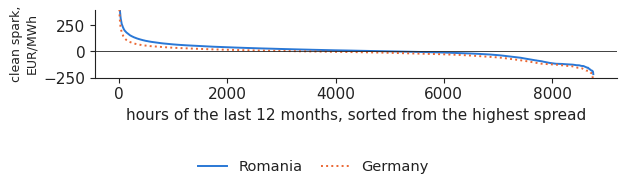

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 2.0))
for z, col, ls, nm in [('RO', PAL['RO'], '-', 'Romania'), ('DE_LU', PAL['DE_LU'], ':', 'Germany')]:
    s = (HH[z] - HH['c']).dropna()
    w = HH.loc[s.index, 'w']
    o = np.argsort(-s.values)
    ax.plot(np.cumsum(w.values[o]), s.values[o], color=col, ls=ls, lw=1.4, label=nm)
ax.axhline(0, color='#222222', lw=0.6)
ax.set_ylim(-250, 400)
ax.set_xlabel('hours of the last 12 months, sorted from the highest spread')
ax.set_ylabel('clean spark,\nEUR/MWh', fontsize=9)
legend_bottom(fig, ncol=2)
fig.tight_layout(rect=(0, 0.24, 1, 1))
plt.savefig('spark_hourly.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()